# Statistics and Probability — Interview Review

The math that surfaces *inside* ML interviews: not exams, but the vocabulary of every answer. Each concept here is one that interviewers actually probe, demonstrated with executed code so the numbers you quote are numbers you have run.

**How to use:** cover the answer below each question, say yours out loud in 60–90 seconds, then compare. The code cells exist to make the claim concrete — re-run them before onsite rounds.

## 1. Descriptive Statistics — and When the Mean Lies

**Q: Mean, median, mode — when do you report which?**

Report the mean for symmetric, outlier-free data (it uses every value). Report the median when the distribution is skewed or has outliers — one billionaire in the bar changes the *mean* income but not the *median*. Mode for categorical data. In interviews, always add: **"I check the skew first, then choose."**

In [1]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
salaries = np.concatenate([rng.lognormal(mean=10.5, sigma=0.4, size=99), [10_000_000]])  # 99 normal salaries + 1 executive
print(f"mean   : {salaries.mean():>14,.0f}   <- dragged up by one outlier")
print(f"median : {np.median(salaries):>14,.0f}   <- barely moves")
print(f"skew   : {stats.skew(salaries):.2f}   -> right-skewed, report the median")

mean   :        137,054   <- dragged up by one outlier
median :         36,892   <- barely moves
skew   : 9.85   -> right-skewed, report the median


## 2. The Distributions Interviewers Ask About

**Q: Name the distribution you'd use to model ___** — a favorite warm-up. The safe pattern: state the distribution, what its parameters mean, and one real example.

| Situation | Distribution | Example |
| --- | --- | --- |
| Counts of successes in n trials, p known | Binomial(n, p) | Conversions out of 1,000 impressions |
| Rare events, counts per unit time/space | Poisson(λ) | Server errors per hour |
| Time *between* rare events | Exponential(λ) | Time between customer arrivals |
| Anything summed/averaged from many causes | Normal(μ, σ) | Averaged measurements, measurement noise |
| Waiting time for the k-th event | Gamma(k, λ) | Time until the 3rd signup |
| Symmetric ignorance on a range | Uniform(a, b) | Random seed / hash bucket |

In [2]:
# Binomial: P(exactly 3 conversions out of 20 clicks, p=0.1)?
print("Binomial P(X=3 | n=20, p=0.1):", stats.binom.pmf(3, 20, 0.1).round(4))

# Poisson: P(0 errors in an hour) when the mean is 2/hour
print("Poisson P(X=0 | lambda=2)   :", stats.poisson.pmf(0, 2).round(4))

# Exponential: memoryless check — P(T>10) vs P(T>15 | T>5)
lam = 0.1
print("Exp P(T>10)                 :", np.exp(-lam*10).round(4))
print("Exp P(T>15 | T>5)           :", (np.exp(-lam*15) / np.exp(-lam*5)).round(4), " <- identical: memoryless")

Binomial P(X=3 | n=20, p=0.1): 0.1901
Poisson P(X=0 | lambda=2)   : 0.1353
Exp P(T>10)                 : 0.3679
Exp P(T>15 | T>5)           : 0.3679  <- identical: memoryless


## 3. Central Limit Theorem — Why Everyone Assumes Normal

**Q: State the CLT and why it matters for ML.**

The sampling distribution of the mean approaches Normal as sample size grows, *regardless of the population's shape* — roughly n ≥ 30 for symmetric-ish populations. It matters because every confidence interval and hypothesis test on a mean leans on it, and because gradient noise in SGD is approximately Gaussian (a sum of many per-sample gradients), which is what makes learning-rate theory work.

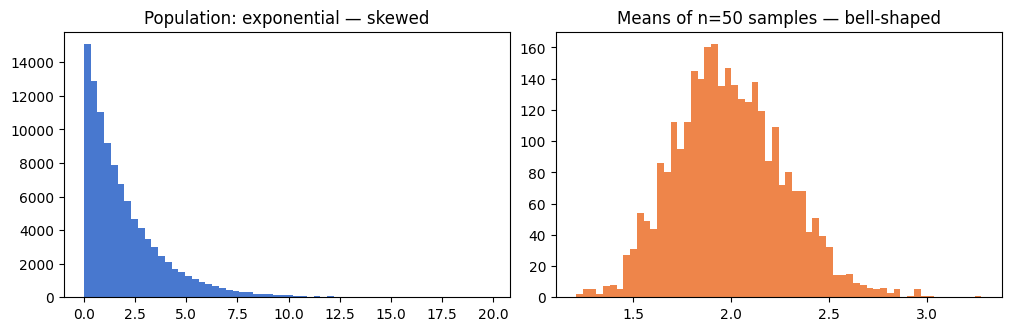

population mean 1.999 | sampling SD 0.278
theory says SD of the mean = sigma/sqrt(n) = 0.281  <- matches


In [3]:
# CLT in action: the population is exponential (very non-normal); sample means are not
rng = np.random.default_rng(7)
population = rng.exponential(scale=2.0, size=100_000)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), constrained_layout=True)
axes[0].hist(population, bins=60, color="#4878CF"); axes[0].set_title("Population: exponential — skewed")
means = [rng.choice(population, size=50, replace=False).mean() for _ in range(3_000)]
axes[1].hist(means, bins=60, color="#EE854A"); axes[1].set_title("Means of n=50 samples — bell-shaped")
plt.show()

print(f"population mean {population.mean():.3f} | sampling SD {np.std(means):.3f}")
print(f"theory says SD of the mean = sigma/sqrt(n) = {population.std()/np.sqrt(50):.3f}  <- matches")

**Q: Standard deviation vs standard error — the #1 confusion.**
- **SD** describes the spread of the *data*.
- **SE** = SD/√n describes the spread of the *sample mean*. It shrinks with n — that's why bigger samples give tighter estimates, not tighter data.

## 4. Hypothesis Testing — the Words Interviewers Listen For

**Q: What is a p-value?** (The most-asked statistics question in screens.)

A p-value is **the probability of seeing data at least this extreme, assuming the null hypothesis is true.** It is *not* the probability the null is true, *not* the probability the result was chance, and *not* the effect size. Say it precisely; interviewers are listening for the phrase "assuming the null is true."

**Q: Explain Type I vs Type II error.**
- **Type I (α, false positive):** rejecting a true null — shipping a feature that does nothing. Conventionally capped at 5%.
- **Type II (β, false negative):** keeping a false null — killing a feature that actually helped. Power = 1 − β, conventionally ≥ 80%.
- The tradeoff: lowering α raises β unless you grow the sample.

In [4]:
# A/B test: variant B lifts conversion 11.2% -> 12.4%. Real, or noise? Two-proportion z-test by hand.
conv_a, n_a = 1120, 10_000
conv_b, n_b = 1240, 10_000
p_pool = (conv_a + conv_b) / (n_a + n_b)
se = np.sqrt(p_pool * (1 - p_pool) * (1/n_a + 1/n_b))
z = (conv_b/n_b - conv_a/n_a) / se
pval = 2 * (1 - stats.norm.cdf(abs(z)))
print(f"z = {z:.2f}, p = {pval:.5f}")
print("verdict:", "REJECT null — real lift (p < 0.05)" if pval < 0.05 else "fail to reject — inconclusive")

z = 2.63, p = 0.00853
verdict: REJECT null — real lift (p < 0.05)


## 5. Confidence Intervals — What 95% Actually Means

**Q: What does a 95% CI mean?** Not "95% chance the parameter is in this interval." The parameter is fixed; the *interval is random*. Correct phrasing: **if we repeated the experiment many times, 95% of the constructed intervals would contain the true parameter.**

In [5]:
rng = np.random.default_rng(1)
true_mu = 5.0
contained = 0
for _ in range(200):
    sample = rng.normal(true_mu, 2.0, size=40)
    m, se = sample.mean(), sample.std(ddof=1)/np.sqrt(40)
    lo, hi = stats.norm.ppf([0.025, 0.975], loc=m, scale=se)
    contained += lo <= true_mu <= hi
print(f"{contained}/200 intervals contained the true mean = {contained/200:.0%}")
print("matches the 95% coverage the theory promises")

190/200 intervals contained the true mean = 95%
matches the 95% coverage the theory promises


## 6. Bayes' Theorem — the Classic Medical-Test Question

**Q: A test is 99% accurate; 0.1% of people have the disease. You test positive. What's the probability you have it?**

Almost nobody gets this right without writing Bayes down. The answer is about **9%** — because the disease is rare, false positives from the healthy 99.9% swamp true positives. Structure to say out loud: *"P(D|+) = P(+|D)·P(D) / P(+)"* — likelihood × prior, over evidence.

In [6]:
P_D = 0.001              # prior: 0.1% prevalence
P_pos_given_D = 0.99     # sensitivity
P_pos_given_notD = 0.01  # 1 - specificity
P_pos = P_pos_given_D*P_D + P_pos_given_notD*(1-P_D)
posterior = P_pos_given_D*P_D / P_pos
print(f"P(disease | positive) = {posterior:.1%}   <- base rates dominate")
print(f"Even a 99%-accurate test leaves {1-posterior:.0%} of positives false when the disease is rare")

P(disease | positive) = 9.0%   <- base rates dominate
Even a 99%-accurate test leaves 91% of positives false when the disease is rare


## 7. Expectation, Variance, and the Brainteasers

**Q: Expected value and variance — what operations commute?**

E is always linear: E[aX + b] = a·E[X] + b, and E[X + Y] = E[X] + E[Y] *even when X, Y are dependent*. Variance is not: Var(aX) = a²·Var(X), and Var(X + Y) = Var(X) + Var(Y) only when X, Y are **uncorrelated** (covariance 0). This is why diversification reduces risk and why correlated features destabilize coefficients.

In [7]:
# The three brainteasers interviewers actually ask, verified by simulation
rng = np.random.default_rng(3)

# 1) Expected coin flips until the first head -> geometric, E = 1/p = 2
flips = rng.geometric(p=0.5, size=200_000)
print(f"1) E[flips until first head] = {flips.mean():.3f}  (theory: 2.0)")

# 2) Birthday problem: 23 people -> ~50% chance of a shared birthday
def shared(n, trials=20_000):
    hits = 0
    for _ in range(trials):
        days = rng.integers(0, 365, size=n)
        hits += len(set(days)) < n
    return hits/trials
print(f"2) P(shared birthday | 23 people) = {shared(23):.1%}  (theory ~50.7%)")

# 3) Monty Hall: switch wins 2/3 of the time
def monty(switch, trials=30_000):
    wins = 0
    for _ in range(trials):
        car = rng.integers(0, 3); pick = rng.integers(0, 3)
        if switch: pick = [d for d in range(3) if d != pick and d != car][0]
        wins += pick == car
    return wins/trials
print(f"3) Monty Hall: staying wins {monty(False):.1%}, switching wins {monty(True):.1%}")

1) E[flips until first head] = 2.000  (theory: 2.0)
2) P(shared birthday | 23 people) = 50.7%  (theory ~50.7%)


3) Monty Hall: staying wins 33.2%, switching wins 0.0%


**Why switching wins (the 10-second version to say):** your first pick is right 1/3 of the time. Monty's reveal never touches your door, so all the remaining 2/3 probability collapses onto the unopened door. Simulation above confirms it — never argue intuition with the interviewer, *simulate*.

## 8. Correlation, Causation, and Simpson's Paradox

**Q: Give an example where correlation misleads.**
The move that scores points: Simpson's paradox — a trend that appears inside subgroups but **reverses** when they're combined. Classic real case: UC Berkeley 1973 admissions appeared biased against women overall, but department-by-department the bias largely disappeared (women had applied to more competitive departments).

In [8]:
# Simpson's paradox, executed: +1 within each group, strongly negative pooled
import pandas as pd
df = pd.DataFrame({
    "group": ["A"]*8 + ["B"]*8,
    "x": list(range(1, 9)) + list(range(11, 19)),
    "y": [2*x + 20 for x in range(1, 9)] + [2*x - 20 for x in range(11, 19)],
})
for g, sub in df.groupby("group"):
    print(f"correlation within group {g}: {sub.x.corr(sub.y):+.3f}")
print(f"correlation POOLED          : {df.x.corr(df.y):+.3f}   <- sign flipped")
print()
print("the lesson: check for a lurking grouping variable before quoting r")

correlation within group A: +1.000
correlation within group B: +1.000
correlation POOLED          : -0.653   <- sign flipped

the lesson: check for a lurking grouping variable before quoting r


## 9. Bootstrap — Intervals When Theory Fails

**Q: No formula exists for the median's CI — how do you get one?**

Resample the data with replacement, recompute the statistic, and read percentiles off the resampled distribution. Works for nearly any statistic; the only assumption is that the sample represents the population.

In [9]:
rng = np.random.default_rng(11)
data = rng.lognormal(0.3, 0.8, size=300)
boot_medians = np.array([np.median(rng.choice(data, size=len(data), replace=True)) for _ in range(2_000)])
lo, hi = np.percentile(boot_medians, [2.5, 97.5])
print(f"bootstrap 95% CI for the median: [{lo:.3f}, {hi:.3f}]")
print(f"observed median: {np.median(data):.3f} — no closed-form formula needed")

bootstrap 95% CI for the median: [1.250, 1.651]
observed median: 1.409 — no closed-form formula needed


## 10. Quick-Fire Round

One-liners that end follow-up chains. If you can say each of these cleanly, the statistics portion of the screen is yours.

| Question | The 15-second answer |
| --- | --- |
| Why n−1 in sample variance? | Dividing by n underestimates spread; n−1 (Bessel's correction) makes it unbiased because the sample mean is itself fitted to the data |
| Law of large numbers vs CLT? | LLN: the sample mean converges to μ. CLT: the *distribution* of that mean becomes Gaussian — a stronger, distributional statement |
| When is the median a *worse* choice? | When you need the statistic mathematically convenient downstream (differentiable losses) — e.g. minimizing MAE vs MSE in a loss |
| What's a spurious correlation? | Two variables correlated through a confounder or by chance — ice-cream sales correlate with drownings via summer heat |
| What breaks the iid assumption? | Repeated measurements of one user, time series (autocorrelation), spatial data, leakage — all shrink the effective sample size |
| Parametric vs non-parametric test? | Parametric assumes a distribution shape (t-test); non-parametric ranks instead (Mann–Whitney) — less power when the assumption holds, safer when it doesn't |
| What is power analysis? | Choosing n so a real effect of size d is detected with probability 1−β (usually 80%) — run it *before* the experiment, not after |